# 📘 Notebook 04: ResNet, the Shortcut that Made Depth Work

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Paper: He, Zhang, Ren and Sun (2015)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** The central experiment trains four networks (8 and 32 layers, with and without shortcuts) for 3 epochs on 20,000 Fashion-MNIST images reduced to 14 × 14 pixels: about **four minutes** in total on a laptop processor, under a minute on a Colab GPU. The paper's experiment used CIFAR-10 and ImageNet, networks of up to 152 layers (and 1,202 on CIFAR-10) and days of GPU training; we reproduce its **phenomenon**, the degradation of deep plain networks and its cure, at a scale that fits a lecture. Section 5 uses the official **pretrained ResNet-50** weights (about 100 MB) instead of training it. Results vary slightly between runs and machines.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Describe the **degradation problem**: deeper plain networks that are **worse even on their training data**
- Explain the **residual block**: learn a correction $F(x)$ and add it to the input, $y = F(x) + x$
- Build plain and residual networks of the same depth and **measure** the difference
- Test a popular explanation (vanishing gradients) by **measuring** gradients, and see why the paper rejects it
- Use a pretrained **ResNet-50** and compare its size and speed with VGG-16

> **Prerequisites:** [Notebook 03: AlexNet and VGG](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/03_alexnet_and_vgg.ipynb). Batch normalisation is used throughout; it rescales the outputs of each layer during training and is explained in [From Python to Deep Learning and Fine-Tuning](https://giannis00.github.io/teaching/#deep-learning).
>
> 🔭 **Why this notebook matters:** ResNet won ImageNet in 2015 with 152 layers, eight times deeper than VGG. The *Deep Residual Learning* paper is among the most cited scientific papers of all time, and its shortcut connection is everywhere today: every **Transformer** (Notebook 07), and therefore every large language model, wraps each of its layers in exactly this kind of shortcut.

## 1. The paper

> 📄 K. He, X. Zhang, S. Ren and J. Sun, [*Deep Residual Learning for Image Recognition*](https://arxiv.org/abs/1512.03385), CVPR 2016 (arXiv 2015).

### Intuition first
VGG showed that deeper is better, so why stop at 19 layers? Because when researchers went deeper, something strange happened: a 56-layer network had **higher error than a 20-layer one, even on the training set**. This is not overfitting (overfitting means good on training data, bad on new data). The deeper network was simply **harder to train**.

That is absurd in principle. A 56-layer network could copy the 20-layer one and make its extra 36 layers do nothing (pass their input through unchanged). It exists; the optimiser just cannot find it. Learning "do nothing" with a stack of convolutions and ReLUs turns out to be hard.

He and colleagues made "do nothing" the **default**. Each block computes a **correction** $F(x)$ and adds it to its input:

$$y = F(x) + x$$

If the best thing a block can do is nothing, it only has to learn $F(x) = 0$, which is easy: push its weights towards zero. The input always has a direct path, the **shortcut**, around the block.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gzip
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
print("PyTorch", torch.__version__)

PyTorch 2.2.2+cpu


## 2. Plain and residual blocks

The two blocks below are identical except for one line: the residual block **adds its input** before the final ReLU.

In [2]:
class Block(nn.Module):
    def __init__(self, channels, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
        self.residual = residual

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + x          # the shortcut: the only difference
        return F.relu(out)

class Net(nn.Module):
    """A stem convolution, `blocks` blocks of two convolutions, average pooling and a classifier."""

    def __init__(self, blocks, residual, channels=16):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, channels, 3, padding=1, bias=False), nn.BatchNorm2d(channels), nn.ReLU())
        self.blocks = nn.Sequential(*[Block(channels, residual) for _ in range(blocks)])
        self.fc = nn.Linear(channels, 10)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

count = lambda m: sum(p.numel() for p in m.parameters())
for blocks in [3, 15]:
    print(f"{2 * blocks + 2} layers: plain {count(Net(blocks, False)):,} weights, residual {count(Net(blocks, True)):,} weights")

8 layers: plain 14,362 weights, residual 14,362 weights
32 layers: plain 70,426 weights, residual 70,426 weights


**What we see.** Adding the shortcut costs **nothing**: plain and residual networks of the same depth have exactly the same number of weights (14,362 for 8 layers, 70,426 for 32). The shortcut is just an addition. Any difference we measure next is due to the architecture, not to size.

## 3. Reproducing the degradation problem

We train four networks with identical settings: 8 and 32 layers, plain and residual. The data is Fashion-MNIST (Notebook 08 of *From Questions to Answers*), reduced to 14 × 14 pixels and 20,000 training images so that the experiment runs in minutes.

In [3]:
BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)
def images(name):
    return F.avg_pool2d(torch.tensor(read_idx(name, 16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255, 2)

X = images("train-images-idx3-ubyte.gz")[:20000]
y = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)[:20000]
X_test = images("t10k-images-idx3-ubyte.gz")
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)

def train(model, epochs=3, batch=128):
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    curve, start = [], time.time()
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(X))
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            out = model(X[idx])
            loss = F.cross_entropy(out, y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            curve.append((out.argmax(1) != y[idx]).float().mean().item())
    model.eval()
    with torch.no_grad():
        test_error = (model(X_test).argmax(1) != y_test).float().mean().item()
    return np.array(curve), test_error, time.time() - start

results = {}
for blocks in [3, 15]:
    for residual in [False, True]:
        torch.manual_seed(0)
        name = f"{2 * blocks + 2} layers, {'residual' if residual else 'plain'}"
        curve, test_error, seconds = train(Net(blocks, residual))
        results[name] = (curve, test_error)
        last_epoch = curve[-len(curve) // 3:].mean()
        print(f"{name:22s} training error (last epoch) {last_epoch:.3f}   test error {test_error:.3f}   {seconds:.0f} s")

8 layers, plain        training error (last epoch) 0.184   test error 0.226   24 s


8 layers, residual     training error (last epoch) 0.188   test error 0.219   23 s


32 layers, plain       training error (last epoch) 0.265   test error 0.308   114 s


32 layers, residual    training error (last epoch) 0.185   test error 0.214   131 s


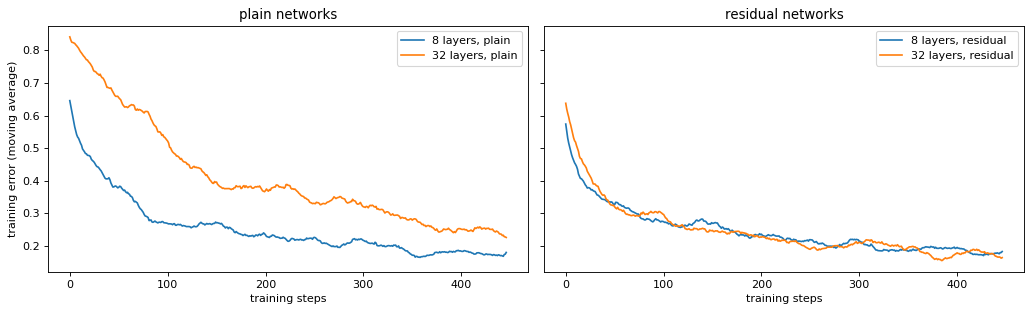

In [4]:
smooth = lambda c: np.convolve(c, np.ones(25) / 25, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, kind in zip(axes, ["plain", "residual"]):
    for name, (curve, _) in results.items():
        if kind in name:
            ax.plot(smooth(curve), label=name)
    ax.set_title(f"{kind} networks")
    ax.set_xlabel("training steps")
    ax.legend()
axes[0].set_ylabel("training error (moving average)")
plt.tight_layout()
plt.show()

**What we see.** This is the paper's Figure 1, at small scale:
- With **8 layers**, plain and residual networks behave the same (about **18.5%** training error in the last epoch, test error 22.6% and 21.9%).
- The **32-layer plain** network is clearly **worse**: **26.5%** training error and **30.8%** test error. Four times the depth made it worse at fitting even the data it trains on. This is **degradation**, not overfitting.
- The **32-layer residual** network trains as well as the 8-layer ones (**18.5%** training error) and has the best test error, **21.4%**.

In the plot, the plain 32-layer curve stays above the others throughout training, while the two residual curves lie on top of each other.

## 4. Why does it work? Testing a popular explanation

### Intuition first
A common explanation is **vanishing gradients**: in a plain network the gradient is multiplied by each layer's derivatives on its way back, so after 30 layers it becomes too small for the first layers to learn. A shortcut adds a second path: since $y = F(x) + x$, the gradient of $y$ with respect to $x$ is the gradient through $F$ **plus 1**, so part of the signal always passes back unchanged.

The paper itself is careful here: it argues that with **batch normalisation** the gradients do **not** vanish, and that degradation is a harder optimisation problem. We can check this ourselves. We measure the size of the gradient that reaches the first layer (the stem) and the last block, at the start of training, for the two 32-layer networks.

In [5]:
def gradient_sizes(residual, batch=256):
    torch.manual_seed(0)
    model = Net(15, residual)
    model.train()
    loss = F.cross_entropy(model(X[:batch]), y[:batch])
    loss.backward()
    first = model.stem[0].weight.grad.norm().item()
    last = model.blocks[-1].conv2.weight.grad.norm().item()
    return first, last

for residual in [False, True]:
    first, last = gradient_sizes(residual)
    print(f"32 layers, {'residual' if residual else 'plain   '}: gradient at first layer {first:.4f}, at last block {last:.4f}, ratio first/last {first / last:.2f}")

32 layers, plain   : gradient at first layer 2.6214, at last block 0.1232, ratio first/last 21.27


32 layers, residual: gradient at first layer 0.4420, at last block 0.2615, ratio first/last 1.69


**What we see.** The measurement **contradicts** the popular explanation and agrees with the paper. In the plain network the gradient at the first layer is not small at all: **2.62**, about **21 times** larger than at the last block (0.12). In the residual network the gradients are much more **even** across depth: 0.44 at the first layer and 0.26 at the last block, a ratio of only **1.7**.

So, with batch normalisation, the plain network's problem is not that its early layers receive no signal, but that the signal is badly **balanced**: the layers near the input receive large, noisy updates, those near the output small ones, and the whole stack struggles to settle into a good solution. The shortcuts make every block start close to "pass the input through", so the network behaves like a shallow one at the beginning of training and adds depth gradually. The full theory is still a research topic; the practical lesson is to **measure** a claimed mechanism instead of repeating it.

## 5. The real ResNet-50, pretrained

The ImageNet ResNets use the same idea with a few refinements: **bottleneck** blocks (a 1 × 1 convolution shrinks the channels, a 3 × 3 works on fewer channels, a 1 × 1 expands them again) and almost no fully connected layers (global average pooling, then one linear layer).

In [6]:
from torchvision.models import resnet50, ResNet50_Weights, vgg16, VGG16_Weights
from skimage import data as skdata

weights_r = ResNet50_Weights.IMAGENET1K_V1
net_r = resnet50(weights=weights_r, progress=False).eval()
categories = weights_r.meta["categories"]
prepare = weights_r.transforms()
photos = {"cat": skdata.chelsea(), "coffee": skdata.coffee(), "rocket": skdata.rocket()}

def top3(net, image):
    with torch.no_grad():
        p = net(prepare(torch.tensor(image).permute(2, 0, 1))[None]).softmax(1)[0]
    v, i = p.topk(3)
    return [(categories[k], round(val.item(), 3)) for val, k in zip(v, i)]

for name, image in photos.items():
    print(f"{name:8s}", top3(net_r, image))

convs = [m for m in net_r.modules() if isinstance(m, nn.Conv2d)]
print("\nconvolutional layers:", len(convs), "  weights:", f"{count(net_r):,}", "  of which in the final linear layer:", f"{count(net_r.fc):,}")

cat      [('Egyptian cat', 0.607), ('tiger cat', 0.209), ('tabby', 0.182)]
coffee   [('espresso', 0.991), ('cup', 0.004), ('consomme', 0.002)]


rocket   [('missile', 0.485), ('projectile', 0.22), ('drilling platform', 0.15)]

convolutional layers: 53   weights: 25,557,032   of which in the final linear layer: 2,049,000


In [7]:
net_v = vgg16(weights=VGG16_Weights.IMAGENET1K_V1, progress=False).eval()
def ms_per_image(net, repeats=5):
    x = torch.zeros(1, 3, 224, 224)
    with torch.no_grad():
        net(x)
        start = time.time()
        for _ in range(repeats):
            net(x)
    return 1000 * (time.time() - start) / repeats
print("ImageNet top-1 accuracy of these weights, as published by torchvision:")
print(f"  VGG-16:    {VGG16_Weights.IMAGENET1K_V1.meta['_metrics']['ImageNet-1K']['acc@1']}%   {count(net_v) / 1e6:.0f} M weights   {ms_per_image(net_v):.0f} ms per image")
print(f"  ResNet-50: {weights_r.meta['_metrics']['ImageNet-1K']['acc@1']}%   {count(net_r) / 1e6:.0f} M weights   {ms_per_image(net_r):.0f} ms per image")

ImageNet top-1 accuracy of these weights, as published by torchvision:


  VGG-16:    71.592%   138 M weights   287 ms per image


  ResNet-50: 76.13%   26 M weights   129 ms per image


**What we see.** ResNet-50 has **53** convolutional layers and **25.6 million** weights, of which only **2 million** are in its single final linear layer: the huge fully connected layers of AlexNet and VGG are gone. Its predictions are confident and sensible (espresso **99%**, missile for the rocket like VGG). According to the accuracies published with these weights, ResNet-50 is right on **76.1%** of ImageNet's validation images against **71.6%** for VGG-16, with about **a fifth of the weights** (26 M against 138 M) and less than half the time per image on this processor (the milliseconds vary between runs).

## ⚠️ Common pitfalls

- **Confusing degradation with overfitting.** Overfitting is low training error and high test error. Degradation is high **training** error in a deeper network; always look at both.
- **Mismatched shapes in the shortcut.** $F(x) + x$ needs the same shape on both sides. When a block changes the number of channels or the size, the shortcut needs a 1 × 1 convolution (the paper's "projection shortcut").
- **Putting the ReLU in the wrong place.** In the original block the addition comes **before** the final ReLU; applying ReLU to $F(x)$ alone and then adding changes the behaviour.
- **Believing shortcuts make any depth free.** They make deep networks **trainable**; whether the extra depth **helps** depends on the problem and the data.

## ✏️ Exercises

### Exercise 1 (Remove batch normalisation)
Build the 32-layer plain and residual networks **without** batch normalisation (replace each `nn.BatchNorm2d` with `nn.Identity()`), train each for one epoch and compare training errors. Which one still trains?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
def no_bn(model):
    for module in model.modules():
        for name, child in module.named_children():
            if isinstance(child, nn.BatchNorm2d):
                setattr(module, name, nn.Identity())
    return model

for residual in [False, True]:
    torch.manual_seed(0)
    curve, test_error, _ = train(no_bn(Net(15, residual)), epochs=1)
    print("residual" if residual else "plain   ", "last-third training error", round(curve[-len(curve) // 3:].mean(), 3))
```

*Without batch normalisation, the deep plain network typically fails to learn at all (its error stays near 90%, random guessing), while the residual one can still make progress. The shortcut alone already keeps a path open for the signal; batch normalisation and shortcuts together are what made very deep networks routine.*
</details>

### Exercise 2 (Deeper still)
Train a **62-layer** residual network (`Net(30, True)`) with the same settings. Is it better than the 32-layer one on this small problem? What does that tell you?

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
torch.manual_seed(0)
curve, test_error, seconds = train(Net(30, True))
print("62 layers, residual: training error", round(curve[-len(curve) // 3:].mean(), 3), " test error", round(test_error, 3), f" ({seconds:.0f} s)")
```

*The 62-layer residual network trains without trouble, so the degradation problem is gone, but it is not clearly better than 32 layers on 14 × 14 images: the problem does not need that much capacity. Shortcuts make depth possible; data and task decide whether it is useful.*
</details>

### Exercise 3 (Find the shortcuts in ResNet-50)
Print `net_r.layer1[0]`. Find the three convolutions of the bottleneck and the **downsample** module. Why does this first block need a downsample on its shortcut?

In [10]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
print(net_r.layer1[0])
```

*The block goes from 64 to 256 channels (1 × 1 to 64, 3 × 3 on 64, 1 × 1 to 256). The input still has 64 channels, so it cannot be added to a 256-channel output directly; the `downsample` (a 1 × 1 convolution with batch normalisation) projects the shortcut to 256 channels. This is the projection shortcut of the paper.*
</details>

## 🔑 Key takeaways

- Very deep **plain** networks suffer from **degradation**: they train worse than shallower ones, even on training data.
- A **residual block** learns a correction and adds it to its input, $y = F(x) + x$; doing nothing becomes the easy default.
- Shortcuts keep training **balanced** across depth; with batch normalisation the plain network's gradients did not vanish, as the paper itself argued.
- With shortcuts and batch normalisation, networks of 50, 152 and even 1,000 layers became trainable.
- ResNet-50 beats VGG-16 on ImageNet with about **a fifth of the weights**; the same shortcut is inside every Transformer.

---
**Next:** *Notebook 05: LSTM*, where depth runs through **time** instead of layers, and a similar trick, an additive memory cell, lets a network remember.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*